# Neural networks: backpropagation with NumPy

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/neural-networks/02-backpropagation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

This notebook implements backpropagation for a small binary-classification neural network using only NumPy. We use the same $2 \rightarrow 3 \rightarrow 1$ architecture as the interactive explorer: two inputs, three ReLU hidden units, and one sigmoid output unit.


## What you will do

1. Create a two-class half-moons dataset.
2. Implement a forward pass through a $2 \rightarrow 3 \rightarrow 1$ network.
3. Trace the gradients for one labeled observation.
4. Average gradients over the full dataset and update every parameter.
5. Watch the loss and the learned probability field change over 50 gradient-descent updates.


## 1. A small half-moons classification problem

The two coordinates are toy input features, and the label is either 0 or 1. This intentionally small example lets us see every intermediate array. Unlike the gas-turbine examples, this is not intended as a realistic mechanical-system model.


In [1]:
import matplotlib.pyplot as plt
import numpy as np


def make_half_moons(*, points_per_class: int = 44) -> tuple[np.ndarray, np.ndarray]:
    """Create a deterministic two-class half-moons dataset.

    Args:
        points_per_class: Number of observations in each moon.

    Returns:
        A tuple containing a feature matrix with shape (n, 2) and a
        column-vector label array with shape (n, 1).
    """
    fractions = np.linspace(0.0, 1.0, points_per_class)
    angles = np.pi * fractions
    wobble = 0.055 * np.sin(np.arange(points_per_class) * 2.3)

    positive = np.column_stack((
        -0.55 + np.cos(angles),
        0.35 + np.sin(angles) + wobble,
    ))
    negative = np.column_stack((
        0.55 - np.cos(angles),
        -0.35 - np.sin(angles) - wobble,
    ))

    features = np.empty((2 * points_per_class, 2), dtype=float)
    labels = np.empty((2 * points_per_class, 1), dtype=float)
    features[0::2] = positive
    features[1::2] = negative
    labels[0::2, 0] = 1.0
    labels[1::2, 0] = 0.0
    return features, labels


X, Y = make_half_moons()
print(f"X shape: {X.shape}")
print(f"Y shape: {Y.shape}")


X shape: (88, 2)
Y shape: (88, 1)


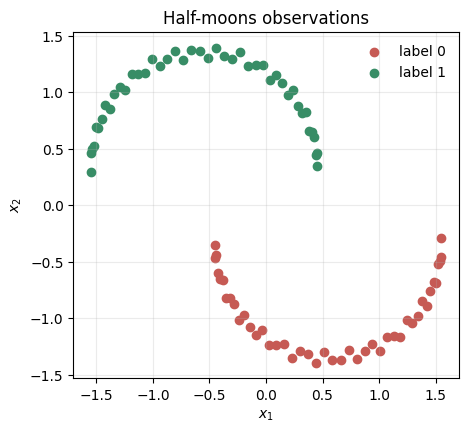

In [2]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(X[Y[:, 0] == 0, 0], X[Y[:, 0] == 0, 1], color="#c65a54", label="label 0")
ax.scatter(X[Y[:, 0] == 1, 0], X[Y[:, 0] == 1, 1], color="#388d66", label="label 1")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Half-moons observations")
ax.legend(frameon=False)
ax.set_aspect("equal")
ax.grid(alpha=0.25)
plt.show()


## 2. Define the network and its forward pass

For a batch of $n$ observations, use the row-wise convention from the lecture:

$$
\begin{aligned}
Z^{[1]} &= X(W^{[1]})^T + B^{[1]}, & A^{[1]} &= \operatorname{ReLU}(Z^{[1]}),\\
Z^{[2]} &= A^{[1]}(W^{[2]})^T + B^{[2]}, & A^{[2]} &= \sigma(Z^{[2]}).
\end{aligned}
$$

The trainable bias vectors are $b^{[1]}$ and $b^{[2]}$. NumPy broadcasts them across observations to form $B^{[1]}$ and $B^{[2]}$.


In [3]:
Parameters = dict[str, np.ndarray]
Gradients = dict[str, np.ndarray]


def relu(values: np.ndarray) -> np.ndarray:
    """Apply ReLU independently to each entry.

    Args:
        values: Array of real-valued hidden-layer scores.

    Returns:
        An array with negative entries replaced by zero.
    """
    return np.maximum(values, 0.0)


def relu_derivative(values: np.ndarray) -> np.ndarray:
    """Return the elementwise derivative of ReLU.

    Args:
        values: Array of ReLU pre-activation scores.

    Returns:
        An array of ones where `values` is positive and zeros otherwise.
    """
    return (values > 0.0).astype(float)


def sigmoid(values: np.ndarray) -> np.ndarray:
    """Map output scores to probabilities.

    Args:
        values: Array of real-valued output scores.

    Returns:
        An array with entries strictly between zero and one.
    """
    clipped_values = np.clip(values, -40.0, 40.0)
    return 1.0 / (1.0 + np.exp(-clipped_values))


def forward_pass(features: np.ndarray, parameters: Parameters) -> tuple[np.ndarray, dict[str, np.ndarray]]:
    """Compute predictions and retain intermediate arrays for backpropagation.

    Args:
        features: Input feature matrix with shape (n, 2).
        parameters: Dictionary containing W1, b1, W2, and b2.

    Returns:
        A tuple containing predicted probabilities with shape (n, 1) and
        the intermediate arrays needed for the backward pass.
    """
    z1 = features @ parameters["W1"].T + parameters["b1"]
    a1 = relu(z1)
    z2 = a1 @ parameters["W2"].T + parameters["b2"]
    a2 = sigmoid(z2)
    return a2, {"X": features, "Z1": z1, "A1": a1, "Z2": z2, "A2": a2}


In [4]:
parameters: Parameters = {
    "W1": np.array([[1.2, -0.8], [-1.0, 1.1], [0.4, -0.5]]),
    "b1": np.array([[0.1, 0.25, 0.2]]),
    "W2": np.array([[1.4, 1.1, -0.9]]),
    "b2": np.array([[-0.6]]),
}

initial_probabilities, initial_cache = forward_pass(X, parameters)
for name, array in initial_cache.items():
    print(f"{name:>2}: {array.shape}")


 X: (88, 2)
Z1: (88, 3)
A1: (88, 3)
Z2: (88, 1)
A2: (88, 1)


## 3. Backpropagate one observation

With sigmoid output activation and binary cross-entropy, the output-layer error signal simplifies to

$$\delta^{[2]} = A^{[2]} - Y.$$

The hidden-layer error signal carries that error backward through the output weights, then applies the ReLU derivative:

$$\delta^{[1]} = (\delta^{[2]} W^{[2]}) \odot \operatorname{ReLU}'(Z^{[1]}).$$

For a single observation, averaging has no effect because $n=1$.


In [5]:
def binary_cross_entropy(probabilities: np.ndarray, labels: np.ndarray) -> float:
    """Compute mean binary cross-entropy.

    Args:
        probabilities: Predicted positive-label probabilities with shape (n, 1).
        labels: Binary labels with shape (n, 1).

    Returns:
        Mean binary cross-entropy across the observations.
    """
    safe_probabilities = np.clip(probabilities, 1e-8, 1.0 - 1e-8)
    return float(np.mean(-(labels * np.log(safe_probabilities) + (1.0 - labels) * np.log(1.0 - safe_probabilities))))


def loss_and_gradients(
    features: np.ndarray,
    labels: np.ndarray,
    parameters: Parameters,
) -> tuple[float, Gradients, dict[str, np.ndarray]]:
    """Compute the mean loss and its gradients for every parameter.

    Args:
        features: Input feature matrix with shape (n, 2).
        labels: Binary label array with shape (n, 1).
        parameters: Dictionary containing the current network parameters.

    Returns:
        A tuple of mean loss, a dictionary of gradients, and the forward-pass cache.
    """
    probabilities, cache = forward_pass(features, parameters)
    n_observations = features.shape[0]

    delta2 = probabilities - labels
    dW2 = delta2.T @ cache["A1"] / n_observations
    db2 = np.mean(delta2, axis=0, keepdims=True)

    delta1 = (delta2 @ parameters["W2"]) * relu_derivative(cache["Z1"])
    dW1 = delta1.T @ features / n_observations
    db1 = np.mean(delta1, axis=0, keepdims=True)

    gradients: Gradients = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
    return binary_cross_entropy(probabilities, labels), gradients, cache


selected_row = 18
one_loss, one_gradients, one_cache = loss_and_gradients(
    X[selected_row : selected_row + 1],
    Y[selected_row : selected_row + 1],
    parameters,
)

print(f"Selected input: {X[selected_row]}")
print(f"Label: {Y[selected_row, 0]:.0f}")
print(f"Prediction: {one_cache['A2'][0, 0]:.3f}")
print(f"Loss: {one_loss:.3f}")
print(f"delta[2]: {(one_cache['A2'] - Y[selected_row : selected_row + 1])[0, 0]:.3f}")
for name, gradient in one_gradients.items():
    print(f"dL/d{name}: {gradient.shape}")


Selected input: [0.24149649 1.01403711]
Label: 1
Prediction: 0.654
Loss: 0.425
delta[2]: -0.346
dL/dW1: (3, 2)
dL/db1: (1, 3)
dL/dW2: (1, 3)
dL/db2: (1, 1)


## 4. Use the full-dataset gradient

A training update uses every half-moons observation. The formulas above first produce a per-observation error signal; `loss_and_gradients` averages those signals when constructing $dL/dW^{[1]}$, $dL/db^{[1]}$, $dL/dW^{[2]}$, and $dL/db^{[2]}$.

Gradient descent then moves each parameter in the opposite direction:

$$\theta \leftarrow \theta - \eta \frac{\partial L}{\partial \theta}.$$


In [6]:
def update_parameters(
    parameters: Parameters,
    gradients: Gradients,
    learning_rate: float,
) -> Parameters:
    """Return parameters after one gradient-descent update.

    Args:
        parameters: Current network parameters.
        gradients: Mean gradients for the corresponding parameters.
        learning_rate: Positive gradient-descent step size.

    Returns:
        A new parameter dictionary after moving opposite each gradient.
    """
    return {
        name: values - learning_rate * gradients[name]
        for name, values in parameters.items()
    }


full_loss, full_gradients, _ = loss_and_gradients(X, Y, parameters)
print(f"Initial full-dataset loss: {full_loss:.3f}")
for name, gradient in full_gradients.items():
    print(f"dL/d{name}: shape {gradient.shape}, mean {gradient.mean():+.4f}")


Initial full-dataset loss: 0.751
dL/dW1: shape (3, 2), mean -0.0240
dL/db1: shape (1, 3), mean +0.0096
dL/dW2: shape (1, 3), mean +0.2568
dL/db2: shape (1, 1), mean +0.2203


## 5. Train for 50 full-batch updates

We start from the fixed parameters above. Each update computes the full-dataset gradient, then changes all weights and biases once. This is full-batch gradient descent, not stochastic gradient descent.


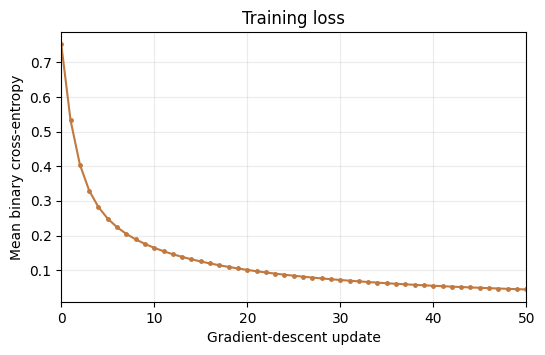

Loss before training: 0.751
Loss after 50 updates: 0.044


In [7]:
learning_rate = 0.20
n_updates = 50
trained_parameters = {name: values.copy() for name, values in parameters.items()}
loss_history = []

for _ in range(n_updates + 1):
    loss, gradients, _ = loss_and_gradients(X, Y, trained_parameters)
    loss_history.append(loss)
    if len(loss_history) <= n_updates:
        trained_parameters = update_parameters(trained_parameters, gradients, learning_rate)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(n_updates + 1), loss_history, color="#c1793f", marker="o", markersize=2.5)
ax.set(xlabel="Gradient-descent update", ylabel="Mean binary cross-entropy", title="Training loss")
ax.set_xlim(0, n_updates)
ax.grid(alpha=0.25)
plt.show()

print(f"Loss before training: {loss_history[0]:.3f}")
print(f"Loss after {n_updates} updates: {loss_history[-1]:.3f}")


## 6. Inspect the learned probability field

The colored background shows $A^{[2]}$, the model's predicted probability of label 1. The network was never told an explicit boundary shape; it changed its weights and biases using gradients of the loss.


Training accuracy after 50 updates: 100.0%


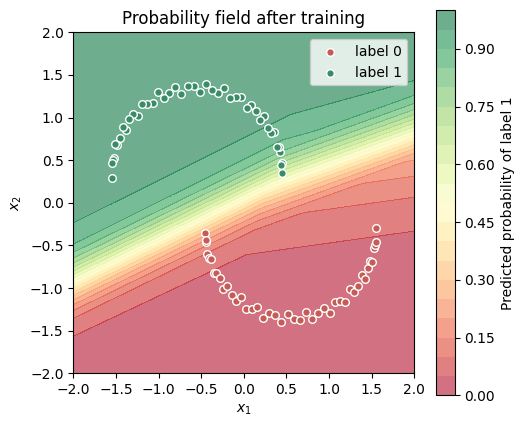

In [8]:
def plot_probability_field(
    features: np.ndarray,
    labels: np.ndarray,
    parameters: Parameters,
) -> None:
    """Plot the network probability field and the labeled observations.

    Args:
        features: Observed two-dimensional feature matrix.
        labels: Binary labels corresponding to `features`.
        parameters: Fitted network parameters used to compute probabilities.
    """
    axis_values = np.linspace(-2.0, 2.0, 180)
    x1_grid, x2_grid = np.meshgrid(axis_values, axis_values)
    grid_features = np.column_stack((x1_grid.ravel(), x2_grid.ravel()))
    grid_probabilities, _ = forward_pass(grid_features, parameters)

    fig, ax = plt.subplots(figsize=(5.5, 5.0))
    image = ax.contourf(
        x1_grid, x2_grid, grid_probabilities.reshape(x1_grid.shape),
        levels=np.linspace(0.0, 1.0, 21), cmap="RdYlGn", alpha=0.58,
    )
    ax.scatter(features[labels[:, 0] == 0, 0], features[labels[:, 0] == 0, 1], color="#c65a54", edgecolor="white", s=30, label="label 0")
    ax.scatter(features[labels[:, 0] == 1, 0], features[labels[:, 0] == 1, 1], color="#388d66", edgecolor="white", s=30, label="label 1")
    fig.colorbar(image, ax=ax, label="Predicted probability of label 1")
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Probability field after training", xlim=(-2, 2), ylim=(-2, 2))
    ax.set_aspect("equal")
    ax.legend(frameon=True, loc="upper right")
    plt.show()


trained_probabilities, _ = forward_pass(X, trained_parameters)
training_accuracy = np.mean((trained_probabilities >= 0.5) == Y)
print(f"Training accuracy after {n_updates} updates: {training_accuracy:.1%}")
plot_probability_field(X, Y, trained_parameters)


## 7. Build and train a deeper network with PyTorch

The NumPy implementation exposed every intermediate array and every gradient. In practice, a library such as [PyTorch](https://pytorch.org/) keeps the same forward-pass and gradient-descent logic, while its automatic differentiation system computes the gradients.

We now use two intertwined spirals. This pattern is deliberately more complicated than the half moons: the small $2 \to 3 \to 1$ network has too few ReLU regions to represent it well. We will compare that small network with a deeper, wider $2 \to 24 \to 24 \to 1$ network. All points are used for training here so that the comparison isolates model capacity rather than generalization.

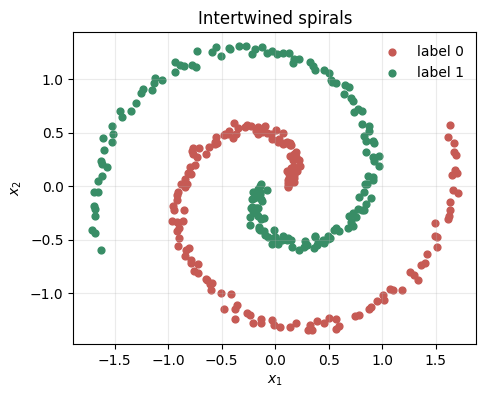

In [9]:
import torch
from torch import nn


def make_intertwined_spirals(
    *,
    points_per_class: int = 160,
    noise_scale: float = 0.035,
    random_seed: int = 7,
) -> tuple[np.ndarray, np.ndarray]:
    """Create a deterministic binary-classification dataset of two spirals.

    Args:
        points_per_class: Number of observations in each spiral.
        noise_scale: Standard deviation of the coordinate perturbation.
        random_seed: Seed used for the perturbation and row ordering.

    Returns:
        A feature matrix with shape (n, 2) and a column-vector label array
        with shape (n, 1).
    """
    generator = np.random.default_rng(random_seed)
    angles = np.linspace(0.15, 1.05 * 2.0 * np.pi, points_per_class)
    radii = np.linspace(0.12, 1.75, points_per_class)

    spiral_zero = np.column_stack((radii * np.cos(angles), radii * np.sin(angles)))
    spiral_one = np.column_stack((radii * np.cos(angles + np.pi), radii * np.sin(angles + np.pi)))
    features = np.vstack((spiral_zero, spiral_one))
    features += generator.normal(scale=noise_scale, size=features.shape)
    labels = np.concatenate((np.zeros(points_per_class), np.ones(points_per_class)))[:, None]

    row_order = generator.permutation(features.shape[0])
    return features[row_order], labels[row_order]


spiral_features, spiral_labels = make_intertwined_spirals()
spiral_features_tensor = torch.tensor(spiral_features, dtype=torch.float32)
spiral_labels_tensor = torch.tensor(spiral_labels, dtype=torch.float32)

fig, ax = plt.subplots(figsize=(5.2, 5.0))
ax.scatter(spiral_features[spiral_labels[:, 0] == 0, 0], spiral_features[spiral_labels[:, 0] == 0, 1], color="#c65a54", s=24, label="label 0")
ax.scatter(spiral_features[spiral_labels[:, 0] == 1, 0], spiral_features[spiral_labels[:, 0] == 1, 1], color="#388d66", s=24, label="label 1")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Intertwined spirals")
ax.set_aspect("equal")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()


### 7.1 Define the two networks

`nn.Linear` represents one affine layer, including both its weights and bias. We leave the final layer as a **logit**—a real-valued score—and use `BCEWithLogitsLoss`, which applies the sigmoid internally in a numerically stable way. At prediction time, we explicitly apply `torch.sigmoid` to convert a logit to a probability.

In [10]:
torch.manual_seed(7)
small_model = nn.Sequential(
    nn.Linear(in_features=2, out_features=3),
    nn.ReLU(),
    nn.Linear(in_features=3, out_features=1),
)

torch.manual_seed(7)
deep_model = nn.Sequential(
    nn.Linear(in_features=2, out_features=24),
    nn.ReLU(),
    nn.Linear(in_features=24, out_features=24),
    nn.ReLU(),
    nn.Linear(in_features=24, out_features=1),
)

print("Small network:")
print(small_model)
print("Deeper network:")
print(deep_model)


Small network:
Sequential(
  (0): Linear(in_features=2, out_features=3, bias=True)
  (1): ReLU()
  (2): Linear(in_features=3, out_features=1, bias=True)
)
Deeper network:
Sequential(
  (0): Linear(in_features=2, out_features=24, bias=True)
  (1): ReLU()
  (2): Linear(in_features=24, out_features=24, bias=True)
  (3): ReLU()
  (4): Linear(in_features=24, out_features=1, bias=True)
)


### 7.2 Train with automatic differentiation

The training loop has the same conceptual steps as the NumPy version: forward pass, binary cross-entropy loss, backward pass, and parameter update. `loss.backward()` performs the backward pass and stores gradients in the model parameters; `optimizer.step()` applies the update.

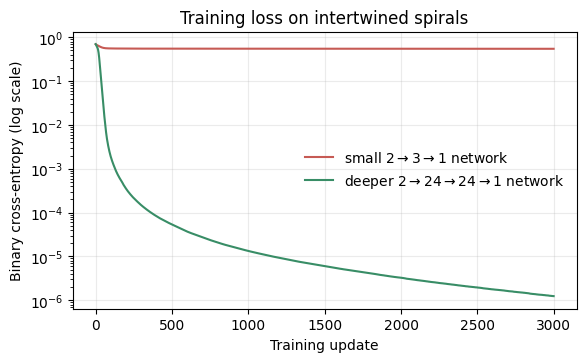

In [11]:
def train_model(
    *,
    model: nn.Module,
    features: torch.Tensor,
    labels: torch.Tensor,
    n_updates: int,
    learning_rate: float,
) -> list[float]:
    """Train a binary classifier with full-batch gradient descent.

    Args:
        model: Neural network mapping two features to one logit.
        features: Input tensor with shape (n, 2).
        labels: Binary column-vector tensor with shape (n, 1).
        n_updates: Number of full-batch optimization updates.
        learning_rate: Adam optimizer step size.

    Returns:
        The binary cross-entropy loss after each update.
    """
    loss_function = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(params=model.parameters(), lr=learning_rate)
    loss_history: list[float] = []

    for _ in range(n_updates):
        optimizer.zero_grad()
        logits = model(features)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())

    return loss_history


small_loss_history = train_model(
    model=small_model,
    features=spiral_features_tensor,
    labels=spiral_labels_tensor,
    n_updates=3_000,
    learning_rate=0.03,
)
deep_loss_history = train_model(
    model=deep_model,
    features=spiral_features_tensor,
    labels=spiral_labels_tensor,
    n_updates=3_000,
    learning_rate=0.02,
)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(small_loss_history, color="#c65a54", label="small $2 \\to 3 \\to 1$ network")
ax.semilogy(deep_loss_history, color="#388d66", label="deeper $2 \\to 24 \\to 24 \\to 1$ network")
ax.set(xlabel="Training update", ylabel="Binary cross-entropy (log scale)", title="Training loss on intertwined spirals")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()


### 7.3 Compare the learned probability fields

A low loss is useful, but the probability fields make the difference tangible. The small network draws only a coarse boundary. The deeper, wider network has enough nonlinear pieces to follow the spiral pattern.

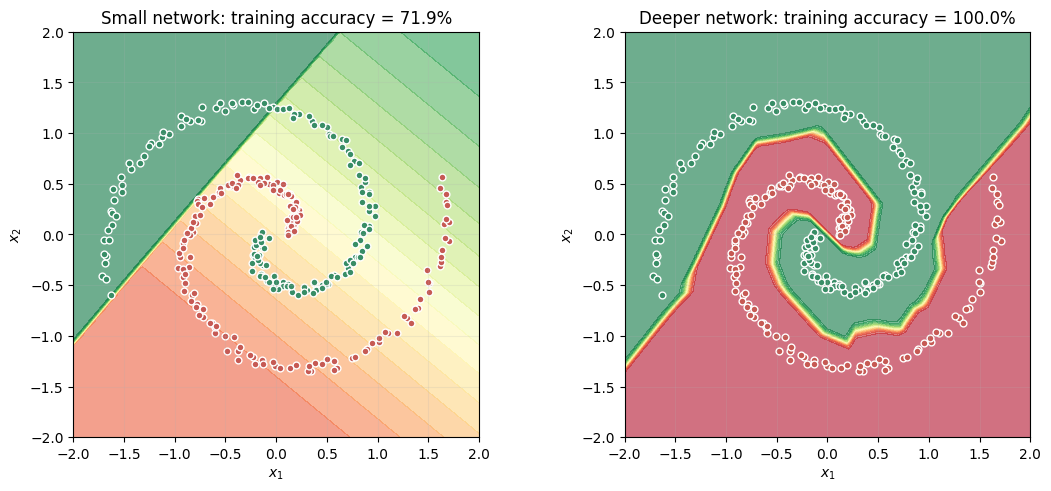

Small-network training accuracy: 71.9%
Deeper-network training accuracy: 100.0%


In [12]:
def torch_accuracy(*, model: nn.Module, features: torch.Tensor, labels: torch.Tensor) -> float:
    """Compute classification accuracy using a probability threshold of 0.5.

    Args:
        model: Trained neural network producing one logit per observation.
        features: Input tensor with shape (n, 2).
        labels: Binary column-vector tensor with shape (n, 1).

    Returns:
        Fraction of observations classified correctly.
    """
    with torch.no_grad():
        probabilities = torch.sigmoid(model(features))
        return ((probabilities >= 0.5) == labels).float().mean().item()


def plot_torch_probability_field(
    *,
    axes: plt.Axes,
    model: nn.Module,
    features: np.ndarray,
    labels: np.ndarray,
    title: str,
) -> None:
    """Plot a PyTorch classifier's predicted probability field.

    Args:
        axes: Matplotlib axes on which to draw.
        model: Trained neural network producing one logit per observation.
        features: Two-dimensional feature matrix.
        labels: Binary column-vector label array.
        title: Panel title.
    """
    axis_values = np.linspace(-2.0, 2.0, 200)
    x1_grid, x2_grid = np.meshgrid(axis_values, axis_values)
    grid_features = np.column_stack((x1_grid.ravel(), x2_grid.ravel()))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        grid_tensor = torch.tensor(grid_features, dtype=torch.float32)
        grid_probabilities = torch.sigmoid(model(grid_tensor)).numpy()
    model.train(mode=was_training)

    axes.contourf(
        x1_grid,
        x2_grid,
        grid_probabilities.reshape(x1_grid.shape),
        levels=np.linspace(0.0, 1.0, 21),
        cmap="RdYlGn",
        alpha=0.58,
    )
    axes.scatter(features[labels[:, 0] == 0, 0], features[labels[:, 0] == 0, 1], color="#c65a54", edgecolor="white", s=24)
    axes.scatter(features[labels[:, 0] == 1, 0], features[labels[:, 0] == 1, 1], color="#388d66", edgecolor="white", s=24)
    axes.set(xlabel="$x_1$", ylabel="$x_2$", title=title, xlim=(-2, 2), ylim=(-2, 2))
    axes.set_aspect("equal")
    axes.grid(alpha=0.18)


small_accuracy = torch_accuracy(model=small_model, features=spiral_features_tensor, labels=spiral_labels_tensor)
deep_accuracy = torch_accuracy(model=deep_model, features=spiral_features_tensor, labels=spiral_labels_tensor)

fig, axes = plt.subplots(ncols=2, figsize=(11.0, 4.8), constrained_layout=True)
plot_torch_probability_field(
    axes=axes[0],
    model=small_model,
    features=spiral_features,
    labels=spiral_labels,
    title=f"Small network: training accuracy = {small_accuracy:.1%}",
)
plot_torch_probability_field(
    axes=axes[1],
    model=deep_model,
    features=spiral_features,
    labels=spiral_labels,
    title=f"Deeper network: training accuracy = {deep_accuracy:.1%}",
)
plt.show()

print(f"Small-network training accuracy: {small_accuracy:.1%}")
print(f"Deeper-network training accuracy: {deep_accuracy:.1%}")


## Takeaway

Backpropagation is an efficient application of the chain rule. A forward pass stores intermediate values; the backward pass begins with the output error $A^{[2]}-Y$ and reuses those values to compute gradients for every weight and bias. Gradient descent then adds many small parameter updates to reduce the loss.
